Today's topics:

* data ethics: ownership, bias, and transparency
* citing Materials Project: license, database version, `theoretical`
* `try` and `except` for a field that is sometimes missing
* measuring missing data with `isna` and `notna`
* random and non-random missing data
* filling in missing values (imputation)
* converting text to numbers with `replace` and `split`

# Where do our numbers come from?

Today we will ask where a dataset came from.
Then we will clean one that has problems.

A handbook value comes with an edition, a table, and a reference.

<img src="https://upload.wikimedia.org/wikipedia/commons/2/2f/CRC_Handbook_of_Chemistry_and_Physics_99th.jpg" alt="Cover of the CRC Handbook of Chemistry and Physics, 99th edition" width="250"/>

*Cover image, public domain, [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:CRC_Handbook_of_Chemistry_and_Physics_99th.jpg).*

Above: the CRC Handbook, a standard reference for property data.

A spreadsheet passed from person to person often has none of that.
Can we still use it?
What do we owe the people who read our results?

# Data ethics

## What is data ethics?

**Data ethics** is the responsible collection, analysis, and sharing of data.

Two views of right and wrong can lead to different judgments:

* **Absolute:** some actions are wrong whatever the outcome, like fabricating data.
* **Relative:** an action is judged by its consequences.

For any dataset we can ask:

* Where did it come from?
* Who owns it, and what may we do with it?
* What does it leave out?

## Ownership and bias

* **Ownership and licensing:** check the license before sharing the data or selling a model built from it.
* **Trade secrets and export control:** NDAs and laws like ITAR limit what we may publish.
* **Bias:** data can be biased even when every number is correct.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/b/b2/Survivorship-bias.svg/960px-Survivorship-bias.svg.png" alt="Outline of a WWII bomber with red dots for bullet holes spread over the wings, tail and fuselage but not the engines" width="450"/>

*Illustration by Martin Grandjean and McGeddon, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Survivorship-bias.svg).*

Above: bullet holes on returning bombers, from Abraham Wald's WWII analysis.
The engines have few holes because those planes did not return.
That is **survivorship bias**.

## Transparency

A careful method does not make data ethical by itself.
Our responsibility is to be **transparent**:

* document the process
* state the assumptions ("missing values were filled with the mean")
* report the limits of the data and the model

Rules vary by jurisdiction.
California has the CCPA.
The EU has the GDPR.

## Case to discuss

A colleague emails you a table of element properties.
It has no source.

May we use it in a report?
What would you ask the colleague first?

# Provenance in Materials Project

Materials Project gives each entry an ID and the database has a version.
Let's see what else it records about where an entry came from.

## Setup

Colab starts a fresh computer each session.
Let's install `mp-api` again.

> ⏳ This could take a few minutes.

In [1]:
!pip install mp-api==0.47.0

In [2]:
#@title Read your Materials Project key (click ▶ to run) { display-mode: "form" }
try:
    from google.colab import userdata
    API_KEY = userdata.get('MaterialsProject')
except ImportError:
    import os
    API_KEY = os.environ['MP_API_KEY']

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mp_api.client import MPRester

## License, version, and the `theoretical` flag

Materials Project data are shared under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
We may share and build on them if we give credit.

Results can change when the database is updated.
We record the database version in the citation.

Every entry has a `theoretical` field.
The ICSD is a database of measured crystal structures.
`False` means the structure matches a reported crystal in the ICSD.
`True` means there is no match.

Every property in Materials Project is still calculated, including the bulk modulus.

Let's request it for every Al-O entry, with the bulk modulus:

In [4]:
with MPRester(API_KEY) as mpr:
    database_version = mpr.db_version
    al_o_docs = mpr.materials.summary.search(
        chemsys='Al-O',  # materials made of Al and O only
        fields=['material_id', 'formula_pretty', 'theoretical', 'bulk_modulus'],
    )

print(database_version)
print(len(al_o_docs))

✓ Retrieved 114 SummaryDoc documents in 1.0s

2026.09.28
114


## A field that is sometimes `None`

Let's look at the bulk modulus of the first entries:

In [5]:
for doc in al_o_docs[:5]:
    print(doc.material_id, doc.bulk_modulus)

mp-1229215 None
mp-8022 {'voigt': 56.23, 'reuss': 56.23, 'vrh': 56.23}
mp-1245110 None
mp-1245215 None
mp-1143 {'voigt': 232.111, 'reuss': 229.896, 'vrh': 231.003}


Some entries have a dictionary with several averages.
Others have `None`, because no elastic calculation was run.

Asking `None` for a key gives an error:

In [6]:
# EXPECTED-ERROR: this cell fails on purpose -- see the surrounding text
missing_entry = None
missing_entry['vrh']

TypeError: 'NoneType' object is not subscriptable

`try` runs the indented line.
If that line raises a `TypeError`, Python runs the `except` block instead of stopping.

This recipe puts `np.nan` where there is no modulus:

In [7]:
records = []
for doc in al_o_docs:
    try:
        bulk_modulus = doc.bulk_modulus['vrh']  # Voigt-Reuss-Hill average in GPa
    except TypeError:
        bulk_modulus = np.nan  # bulk_modulus is None, so there is no value
    records.append({
        'material_id': str(doc.material_id),
        'formula': doc.formula_pretty,
        'theoretical': doc.theoretical,
        'bulk_modulus': bulk_modulus,
    })

al_o = pd.DataFrame(records)
display(al_o.head())

,material_id,formula,theoretical,bulk_modulus
0,mp-1229215,Al11O18,True,NaN
1,mp-8022,Al2O,False,56.230
2,mp-1245110,Al2O,True,NaN
3,mp-1245215,Al2O,True,NaN
4,mp-1143,Al2O3,False,231.003


`notna` and `isna` count the filled and the missing entries:

In [8]:
print(al_o['bulk_modulus'].notna().sum())  # entries with a bulk modulus
print(al_o['bulk_modulus'].isna().sum())   # entries without one

24
90


Let's split the entries by the `theoretical` flag:

In [9]:
theoretical_entries = al_o[al_o['theoretical'] == True]
icsd_entries = al_o[al_o['theoretical'] == False]

print(len(theoretical_entries), theoretical_entries['bulk_modulus'].notna().sum())
print(len(icsd_entries), icsd_entries['bulk_modulus'].notna().sum())  # entries, then entries with a modulus

99 17
15 7


Most Al-O entries are theoretical, and most of them have no modulus.
Only a few match a reported crystal.
Even for those, the modulus is a calculated value.
When we report on real aluminum oxides, we say the moduli are calculated.

## Citing Materials Project

A citation names the paper, the license, and the database version.
We recorded the version above:

> Data from Materials Project (database version 2026.09.28), M. K. Horton et al., *Nature Materials* **24**, 1522 (2025), [doi:10.1038/s41563-025-02272-0](https://doi.org/10.1038/s41563-025-02272-0), CC BY 4.0.

# Data cleaning

## Why clean data?

**Data cleaning** makes raw data fit for analysis.

The steps:

1. **Identification:** find the problems.
2. **Correction:** fix, fill, or remove.
3. **Validation:** check that the fixes make sense.
4. **Documentation:** record what you did.

## A table of element properties

This is the table from our case.
Its source was never recorded.
We cannot trace its values to their original source.

It is still fine for practicing cleaning:

In [10]:
data = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/alloy_cleaning.csv',
                   encoding='cp1252')  # the file was saved as Windows text
display(data)

,number,name,symbol,name_symbol,pronunciation,appearance,atomic_number,group_block,period,element_category,...,band_gap,recognised_as_an_element_by,curie_point,recognized_as_a_unique_metal_by,recognized_as_a_distinct_element_by,thermal_diffusivity,tensile_strength,molar_volume,proposed_formal_name,alternative_names
0,1,Hydrogen,H,"hydrogen, H","/?ha?dr?d??n/, HY-dr?-j?n",colorless gas,1,"group 1, s-block",1,diatomic nonmetal,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Helium,He,"helium, He","/?hi?li?m/, HEE-lee-?m","colorless gas, exhibiting a red-orange glow wh...",2,"group 18 (noble gases), s-block",1,noble gas,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Lithium,Li,"lithium, Li","/?l??i?m/, LI-thee-?m",silvery-white,3,"group 1 (alkali metals), s-block",2,alkali metal,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,Beryllium,Be,"beryllium, Be","/b??r?li?m/, b?-RIL-ee-?m",white-gray metallic,4,"group 2 (alkaline earth metals), s-block",2,alkaline earth metal,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Boron,B,"boron, B",/?b??r?n/,black-brown,5,"group 13, p-block",2,metalloid,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,114,Ununquadium,Uuq,"flerovium, Fl","/fl??ro?vi?m/, fli-ROH-vee-?m",NaN,114,"group 14 (carbon group), p-block",7,post-transition metal,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113,115,Ununpentium,Uup,"ununpentium, Uup","i/u?nu?n?p?nti?m/, oon-oon-PEN-tee-?m",NaN,115,"group 15 (pnictogens), p-block",7,"unknown, but probably a post-transition metal",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"moscovium, Mc","element 115, eka-bismuth"
114,116,Ununhexium,Uuh,"livermorium, Lv","/?l?v?r?m??ri?m/, LIV-?r-MOHR-ee-?m",NaN,116,"group 16 (chalcogens), p-block",7,"unknown, but probably a post-transition metal",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
115,117,Ununseptium,Uus,"ununseptium, Uus","i/u?nu?n?s?pti?m/, oon-oon-SEP-tee-?m",semimetallic (predicted),117,"group 17, p-block",7,"unknown, but probably a post-transition metal",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"tennessine, Ts","element 117, eka-astatine"


In [11]:
print(data.shape)  # rows, columns

(117, 73)


One row per element, and many columns.

Let's count the filled entries in each column:

In [12]:
filled = data.notna().sum()  # filled entries in each column
print(filled)

number                  117
name                    117
symbol                  117
name_symbol             117
pronunciation           117
                       ... 
thermal_diffusivity       2
tensile_strength          2
molar_volume              1
proposed_formal_name      4
alternative_names         4
Length: 73, dtype: int64


`curie_point` has a single value.
Many columns are mostly empty.

# Missing data

## How much is missing?

Let's turn the counts into the fraction missing in each column:

Text(0, 0.5, 'number of columns')

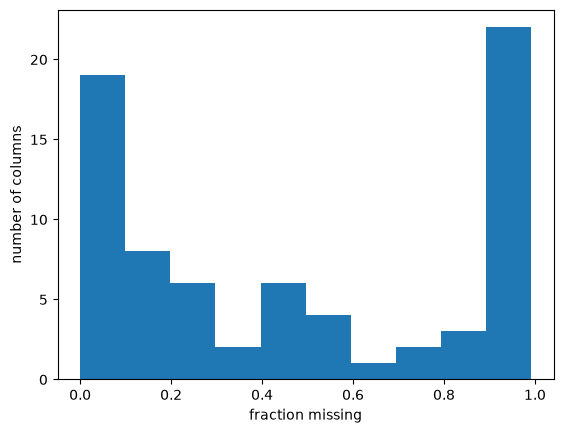

In [13]:
missing_frac = 1 - filled / len(data)

fig, ax = plt.subplots()
ax.hist(missing_frac)
ax.set_xlabel('fraction missing')
ax.set_ylabel('number of columns')

Many columns are nearly full, and many are nearly empty.
The table has no single level of completeness.

## Which rows are missing?

Is a value missing at random, or for a physical reason?

`melting_point` is mostly filled.
Let's count its missing entries:

In [14]:
print(data['melting_point'].isna().sum())

12


Are the missing melting points the heavy elements?
Let's compare the atomic numbers of all elements with those that have a melting point:

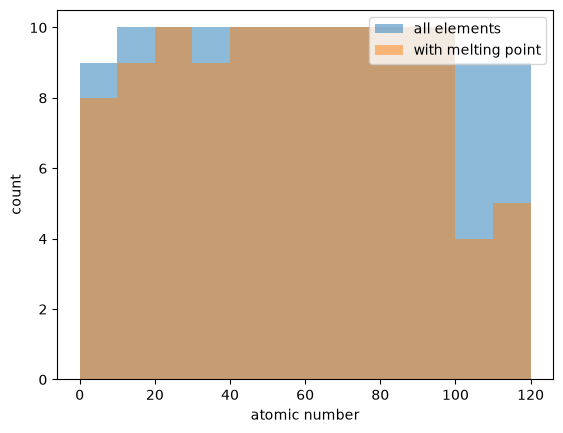

In [15]:
has_melting = data.dropna(subset=['melting_point'])

fig, ax = plt.subplots()
ax.hist(data['atomic_number'], bins=12, range=(0, 120), alpha=0.5, label='all elements')
ax.hist(has_melting['atomic_number'], bins=12, range=(0, 120), alpha=0.5, label='with melting point')
ax.set_xlabel('atomic number')
ax.set_ylabel('count')
ax.legend()

About half of the elements above 100 have no melting point.
Only 3 of the first 100 are missing: C, P, and As.

The heaviest elements are made a few atoms at a time.
A melting point is hard to measure on a few atoms.

These gaps are **not random**: they depend on which element it is.
A model trained on these rows has little data on the heaviest elements.

Let's see all the gaps at once.
`isna()` gives `True` for each missing entry:

Text(0, 0.5, 'row (element)')

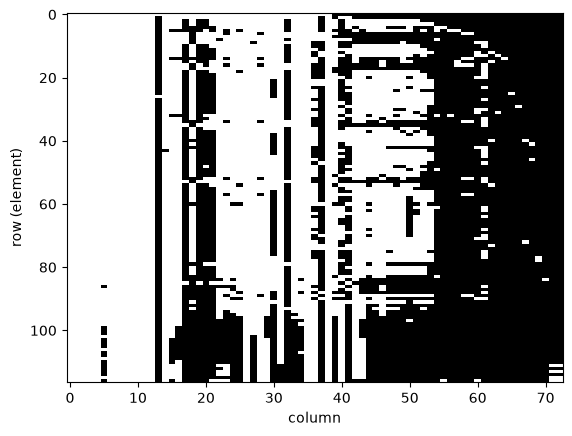

In [16]:
fig, ax = plt.subplots()
ax.imshow(data.isna(), cmap='Greys', aspect='auto')  # black = missing
ax.set_xlabel('column')
ax.set_ylabel('row (element)')

The gaps form blocks.
Whole groups of elements are missing whole groups of properties.

### [Check your understanding]

Let's check another property for how it's missing.

1. Pick a column such as `thermal_conductivity`, `youngs_modulus`, or `band_gap`.
2. Make a DataFrame of the rows where it is filled.
3. Plot the atomic-number histograms of all elements and of the filled rows on one chart.

Do its gaps depend on atomic number?

## Filling in missing values

Filling in missing values is called **imputation**.

The simplest choice is the column mean.
Let's try it on `van_der_waals_radius`:

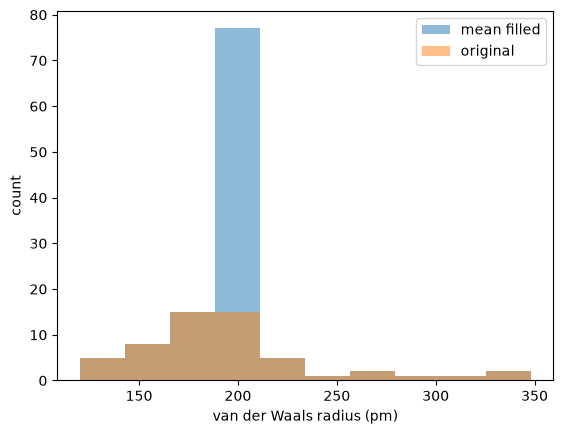

In [17]:
radius = data['van_der_waals_radius']
radius_mean = radius.fillna(radius.mean())  # every NaN becomes the mean

fig, ax = plt.subplots()
ax.hist(radius_mean, alpha=0.5, label='mean filled')
ax.hist(radius, alpha=0.5, label='original')
ax.set_xlabel('van der Waals radius (pm)')
ax.set_ylabel('count')
ax.legend()

More than half of this column was missing.
All of those rows now sit in one bar at the mean.

The data look far less spread out than they are.

The rows are in order of atomic number.
**Forward fill** copies the value from the row above:

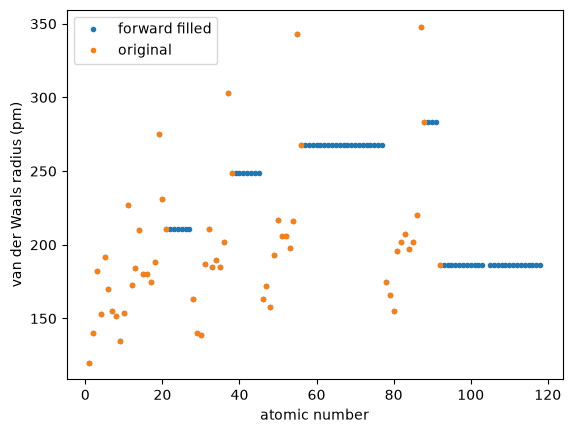

In [18]:
radius_ffill = radius.ffill()  # each NaN takes the value above it

fig, ax = plt.subplots()
ax.plot(data['atomic_number'], radius_ffill, '.', label='forward filled')
ax.plot(data['atomic_number'], radius, '.', label='original')
ax.set_xlabel('atomic number')
ax.set_ylabel('van der Waals radius (pm)')
ax.legend()

Each gap becomes a flat run.
Barium's value now stands in for atomic numbers 57 to 77, the lanthanides and the metals from Hf to Ir.

Neighbors in the table are not always alike.
Whichever fill we use goes into our documentation.

# Text to numbers

## A column of strings

Let's look at `youngs_modulus`:

In [19]:
modulus_text = data['youngs_modulus'].dropna()
print(modulus_text.values)

<ArrowStringArray>
[                '4.9',                 '287',   'diamond: 1050 GPa',
                  '10',                  '45',                  '70',
         '130–188 GPa',                '3.53',                  '20',
                '74.4',                 '116',                 '128',
                 '279',                 '198',                 '211',
                 '209',                 '200',         '110–128 GPa',
                 '108',                 '9.8',                 '103',
                   '8',                  '10',                 '2.4',
                '15.7',                '63.5',                  '88',
                 '105',                 '329',                 '447',
                 '380',                 '121',                  '83',
                  '50',                  '11',                  '50',
                  '55',                  '43',                 '1.7',
                  '13',    '? form: 36.6 GPa',    '? form: 33.6 GPa',
 

Each entry is a string with units and notes.
`float` can't read it:

In [20]:
# EXPECTED-ERROR: this cell fails on purpose -- see the surrounding text
float(modulus_text.values[2])

ValueError: could not convert string to float: 'diamond: 1050 GPa'

## `replace` and `split`

`replace` swaps one piece of a string for another:

In [21]:
sample = 'diamond: 1050 GPa'
print(sample.replace(' GPa', ''))  # replace with nothing

diamond: 1050


`split` breaks a string into a list at each space:

In [22]:
print(sample.replace(' GPa', '').split(' '))

['diamond:', '1050']


The number is the last piece:

In [23]:
pieces = sample.replace(' GPa', '').split(' ')
print(float(pieces[-1]))

1050.0


## A converter for the whole column

Some entries are ranges like `'130–188 GPa'`.
The `–` there is an en dash, a different character from the `-` minus sign.

This converter handles single values and ranges.
It uses `try` and `except` again.
This time the `except` catches a `ValueError` from `float`.

In [24]:
def convert_modulus(text):
    number = text.replace(' GPa', '').split(' ')[-1]  # last piece, unit removed
    try:
        return float(number)
    except ValueError:
        low, high = number.split('–')  # a range: split at the en dash
        return (float(low) + float(high)) / 2  # use the middle of the range


modulus = []
for text in modulus_text:
    modulus.append(convert_modulus(text))

The converter handled every filled entry.

Let's validate.
The count should match.
Diamond should have the largest modulus.

In [25]:
print(len(modulus_text), len(modulus))
print(max(modulus))

68 68
1050.0


Text(0, 0.5, 'count')

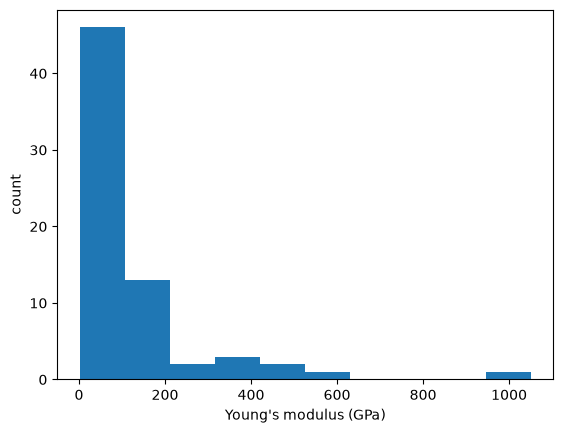

In [26]:
fig, ax = plt.subplots()
ax.hist(modulus)
ax.set_xlabel("Young's modulus (GPa)")
ax.set_ylabel('count')

Before cleaning, the column was strings with units and notes.
The 68 filled entries are now numbers we can plot.

### [Check your understanding]

The `electronegativity` column is text like `'Pauling scale: 2.20'`.
A few entries are `'Pauling scale: no data'`.

1. Write `convert_electronegativity(text)`. Remove `'Pauling scale: '` with `replace`, and return `float` of what is left.
2. Make it return `np.nan` when `float` raises a `ValueError`.
3. Convert every filled entry of the column, and print how many are `NaN`.

Optional: some entries add `(?)`, `>`, or `(predicted)`.
What does your function do with them?

## Documenting what we did

A data note lets readers check the report's limits.
Let's collect the numbers for it:

In [27]:
print(len(data))
print(data['youngs_modulus'].notna().sum())
print(max(modulus))

117
68
1050.0


> **Data note.** Young's modulus comes from an element-property table whose original source is unknown.
> Values should be compared with an independent reference before they are reported.
> It is given for 68 of 117 elements, and the gaps are not random: they include the gases and the heaviest elements.
> Entries with units or notes were converted to numbers by removing the text, and ranges were replaced by their midpoint.
> The largest value is diamond, at 1050 GPa.

Back to our opening question.
A table of unknown source is fine for practicing cleaning.
Its property values need independent checking before we use them: 68 of 117 Young's moduli are filled, and none can be traced to a source.

# Summary

* Data ethics covers where data came from, what we may do with it, and what it leaves out.
* A citation names the license and the database version; `theoretical` is `False` when the structure matches a reported crystal, and its properties are still calculated.
* `try` and `except` handle a line that sometimes fails, such as a field that is `None`.
* `notna()` and `isna()` mark filled and missing entries; `.sum()` counts them.
* Missing data can be random, or depend on which sample it is.
* `fillna` and `ffill` impute missing values; each changes the data.
* `replace` and `split` turn text into pieces that `float` can read.

## Further reading

* pandas, [Working with missing data](https://pandas.pydata.org/docs/user_guide/missing_data.html)
* Python, [String methods](https://docs.python.org/3/library/stdtypes.html#string-methods)
* Python tutorial, [Handling exceptions](https://docs.python.org/3/tutorial/errors.html#handling-exceptions)
* Materials Project, [Database versions](https://docs.materialsproject.org/changes/database-versions)